# Imágenes y Datos

En este notebook generaremos las imágenes necesarias para presentar en la tesis, así como los datos presentados.

In [1]:
# librerias numericas
import pandas as pd
import numpy as np

# librerias de graficas
import matplotlib.pyplot as plt
import seaborn as sns

# librerias ML
from sklearn.preprocessing import StandardScaler # para estandarizar datos
from sklearn.decomposition import PCA # para el PCA

# ajustes del output de pandas
pd.options.display.max_columns = 100 # cuántas columnas se imprimen

In [2]:
# importación de los datos
datos_voltajes = pd.read_csv('../databases/datos_voltaje.csv', index_col='Unnamed: 0')
datos_tiempos = pd.read_csv('../databases/datos_tiempos.csv', index_col='Unnamed: 0')

# corrección de errores
datos_voltajes.loc[2350,'height'] = np.nan

## Datos voltajes

In [4]:
datos_voltajes.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2400 entries, 0 to 2399
Data columns (total 23 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id_ecg      2400 non-null   float64
 1   categoria   2400 non-null   object 
 2   min_RC      2378 non-null   float64
 3   media_RC    2378 non-null   float64
 4   max_RC      2378 non-null   float64
 5   sd_RC       2378 non-null   float64
 6   min_P       2378 non-null   float64
 7   media_P     2378 non-null   float64
 8   max_P       2378 non-null   float64
 9   sd_P        2378 non-null   float64
 10  min_R       2378 non-null   float64
 11  media_R     2378 non-null   float64
 12  max_R       2378 non-null   float64
 13  sd_R        2378 non-null   float64
 14  min_T       2378 non-null   float64
 15  media_T     2378 non-null   float64
 16  max_T       2378 non-null   float64
 17  sd_T        2378 non-null   float64
 18  patient_id  2383 non-null   float64
 19  age         2383 non-null   floa

In [74]:
datos_voltajes.loc[2350,'height'] = np.nan
datos_voltajes[['age','sex','height','weight']].describe()

,age,sex,height,weight
count,2383.000000,2383.000000,1193.000000,1689.000000
mean,63.879564,0.531683,166.798826,70.341622
std,39.691741,0.499100,9.581587,15.180039
min,12.000000,0.000000,135.000000,38.000000
25%,47.000000,0.000000,160.000000,60.000000
50%,62.000000,1.000000,166.000000,70.000000
75%,74.000000,1.000000,174.000000,80.000000
max,300.000000,1.000000,197.000000,163.000000


### Boxplots de ritmo cardiaco

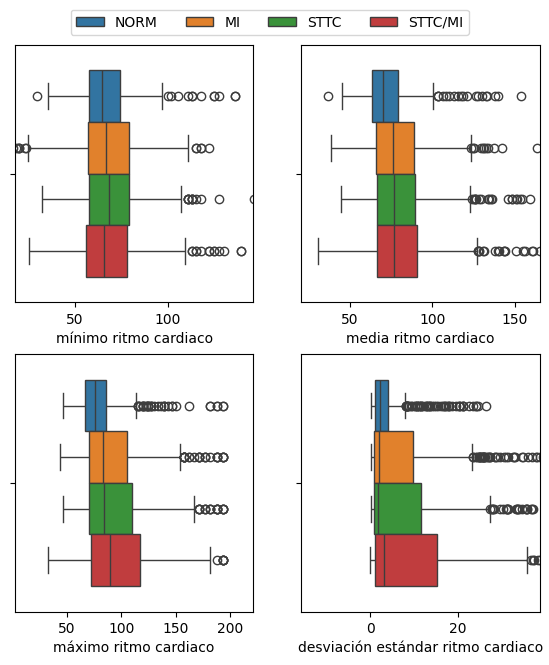

In [5]:
# columnas sobre ritmo cardiaco
columnas = ['min_RC', 'media_RC', 'max_RC', 'sd_RC']
nombres = ['mínimo ritmo cardiaco', 'media ritmo cardiaco', 'máximo ritmo cardiaco', 'desviación estándar ritmo cardiaco']
labels = ['NORM', 'MI', 'STTC', 'STTC/MI']
z = 0

# creamos la figura
fig, axs = plt.subplots(2,2, figsize=(6, 7))

#graficamos con un for
for columna, ubicacion, nombre in zip(columnas, axs.flatten(), nombres):
    Q1,Q3 = np.quantile(datos_voltajes[columna].dropna(),[0.25,0.75])
    RIQ = Q3-Q1
    li = Q1 - 2*RIQ
    ls = Q3 + 3.5*RIQ
    sns.boxplot(datos_voltajes, x=columna, hue='categoria', ax=ubicacion)
    ubicacion.set_xlim([li,ls])
    ubicacion.set_xlabel(nombre)
    ubicacion.get_legend().remove() # quitamos las leyendas individuales de los gráficos
    if z == 0: # para el primer ciclo...
        handles, _ = ubicacion.get_legend_handles_labels() # obtenemos la info de leyendas
        z =+ 1 # cambiamos z para no volver a sacar la info
# agregamos la leyenda global
fig.legend(handles, labels, loc='upper center', ncols=4, bbox_to_anchor=(0.55, 0.98))

# Ajuste manual
plt.subplots_adjust(top=0.92, right=1)
plt.savefig('../imagenes/ritmo_cardiaco.png', dpi=300, bbox_inches='tight')
plt.show()

In [78]:
datos_voltajes[columnas].describe()

,min_RC,media_RC,max_RC,sd_RC
count,2378.000000,2378.000000,2378.000000,2.378000e+03
mean,67.935541,77.582120,90.173157,6.622067e+00
std,16.656463,18.641057,29.199502,8.720716e+00
min,14.184397,30.582870,32.786885,3.798011e-15
25%,57.142857,64.961690,69.767442,1.058970e+00
50%,66.666667,74.417659,82.191781,2.140437e+00
75%,76.923077,87.255626,103.448276,9.433575e+00
max,166.666667,175.112387,193.548387,6.021852e+01


In [80]:
datos_voltajes[datos_voltajes['min_RC'] < 14.19]['categoria']

2022    datos_leonel\mi
Name: categoria, dtype: object

In [93]:
datos_voltajes[datos_voltajes['max_RC'] > 193.54]['categoria'].value_counts()

categoria
datos_leonel\sttc_mi    5
datos_leonel\sttc       4
datos_leonel\mi         4
datos_leonel\other      2
Name: count, dtype: int64

In [97]:
datos_voltajes[datos_voltajes['categoria'] == r'datos_leonel\sttc'][columnas].describe()

,min_RC,media_RC,max_RC,sd_RC
count,592.000000,592.000000,592.000000,592.000000
mean,69.448919,79.563332,93.193946,6.937386
std,16.997077,19.755954,31.226795,8.802352
min,32.432432,44.749487,46.511628,0.211156
25%,57.692308,66.445396,70.588235,0.993666
50%,68.181818,76.787876,84.507042,1.837325
75%,78.947368,89.386207,109.595960,11.568087
max,166.666667,171.635137,193.548387,37.149513


### Boxplots de onda P

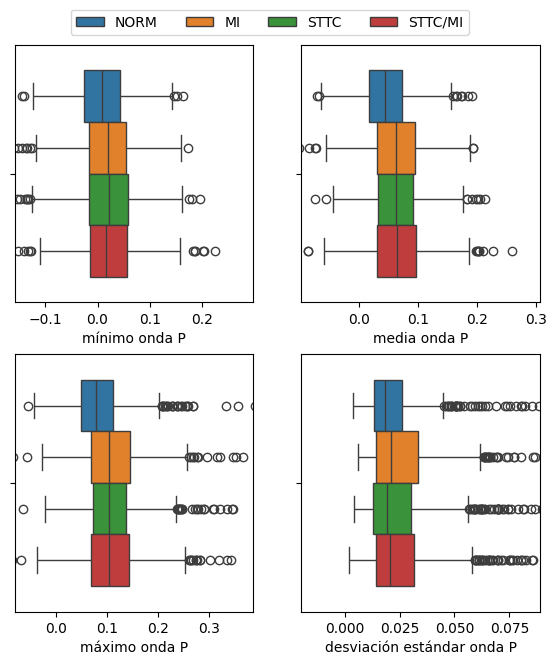

In [6]:
# columnas de la onda
columnas = ['min_P', 'media_P', 'max_P', 'sd_P']
nombres = ['mínimo onda P', 'media onda P', 'máximo onda P', 'desviación estándar onda P']
labels = ['NORM', 'MI', 'STTC', 'STTC/MI']
z = 0

# creamos la figura
fig, axs = plt.subplots(2,2, figsize=(6, 7))

#graficamos con un for
for columna, ubicacion, nombre in zip(columnas, axs.flatten(), nombres):
    Q1,Q3 = np.quantile(datos_voltajes[columna].dropna(),[0.25,0.75])
    RIQ = Q3-Q1
    li = Q1 - 2*RIQ
    ls = Q3 + 3.5*RIQ
    sns.boxplot(datos_voltajes, x=columna, hue='categoria', ax=ubicacion)
    ubicacion.set_xlim([li,ls])
    ubicacion.set_xlabel(nombre)
    ubicacion.get_legend().remove() # quitamos las leyendas individuales de los gráficos
    if z == 0: # para el primer ciclo...
        handles, _ = ubicacion.get_legend_handles_labels() # obtenemos la info de leyendas
        z =+ 1 # cambiamos z para no volver a sacar la info
# agregamos la leyenda global
fig.legend(handles, labels, loc='upper center', ncols=4, bbox_to_anchor=(0.55, 0.98))

# Ajuste manual
plt.subplots_adjust(top=0.92, right=1)
plt.savefig('../imagenes/onda_p.png', dpi=300, bbox_inches='tight')
plt.show()

In [17]:
datos_voltajes[datos_voltajes['categoria']==r'datos_leonel\mi'][columnas].describe()

,min_P,media_P,max_P,sd_P
count,593.000000,593.000000,593.000000,593.000000
mean,0.016986,0.063042,0.110575,0.027521
std,0.056048,0.048174,0.071595,0.022258
min,-0.317382,-0.104726,-0.084690,0.006076
25%,-0.017106,0.030465,0.068009,0.014451
50%,0.019299,0.062983,0.103878,0.020907
75%,0.053534,0.094427,0.143806,0.033624
max,0.171999,0.192739,0.656560,0.211804


In [19]:
(0.063042-0.044850)/0.027521

0.6610224919152647

### Boxplots de onda R

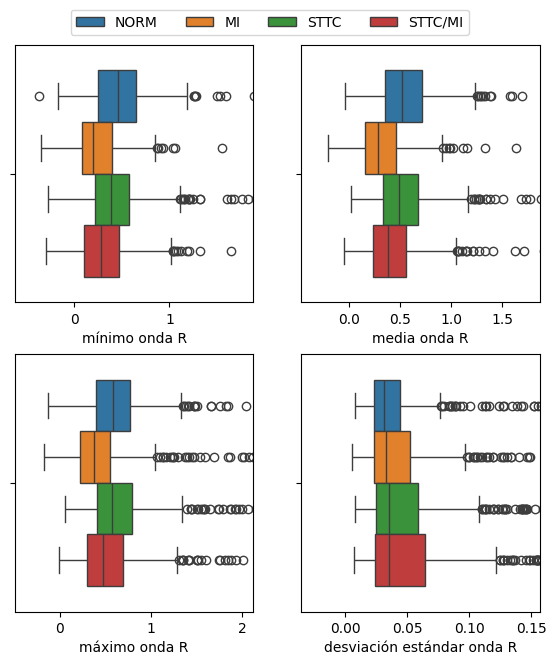

In [21]:
# columnas de la onda
columnas = ['min_R', 'media_R', 'max_R', 'sd_R']
nombres = ['mínimo onda R', 'media onda R', 'máximo onda R', 'desviación estándar onda R']
labels = ['NORM', 'MI', 'STTC', 'STTC/MI']
z = 0

# creamos la figura
fig, axs = plt.subplots(2,2, figsize=(6, 7))

#graficamos con un for
for columna, ubicacion, nombre in zip(columnas, axs.flatten(), nombres):
    Q1,Q3 = np.quantile(datos_voltajes[columna].dropna(),[0.25,0.75])
    RIQ = Q3-Q1
    li = Q1 - 2*RIQ
    ls = Q3 + 3.5*RIQ
    sns.boxplot(datos_voltajes, x=columna, hue='categoria', ax=ubicacion)
    ubicacion.set_xlim([li,ls])
    ubicacion.set_xlabel(nombre)
    ubicacion.get_legend().remove() # quitamos las leyendas individuales de los gráficos
    if z == 0: # para el primer ciclo...
        handles, _ = ubicacion.get_legend_handles_labels() # obtenemos la info de leyendas
        z =+ 1 # cambiamos z para no volver a sacar la info
# agregamos la leyenda global
fig.legend(handles, labels, loc='upper center', ncols=4, bbox_to_anchor=(0.55, 0.98))

# Ajuste manual
plt.subplots_adjust(top=0.92, right=1)
plt.savefig('../imagenes/onda_r.png', dpi=300, bbox_inches='tight')
plt.show()

In [27]:
datos_voltajes[columnas].describe()

,min_R,media_R,max_R,sd_R
count,2378.000000,2378.000000,2378.000000,2378.000000
mean,0.362972,0.455660,0.556050,0.056782
std,0.291261,0.288367,0.351595,0.078592
min,-1.009592,-0.835611,-0.173885,0.005687
25%,0.146285,0.249379,0.311788,0.023896
50%,0.334438,0.423271,0.500980,0.033723
75%,0.532713,0.609097,0.714381,0.053451
max,1.985940,2.283936,2.946908,1.057330


In [28]:
(0.541-0.534)/0.0567

0.1234567901234569

### Boxplots de onda T

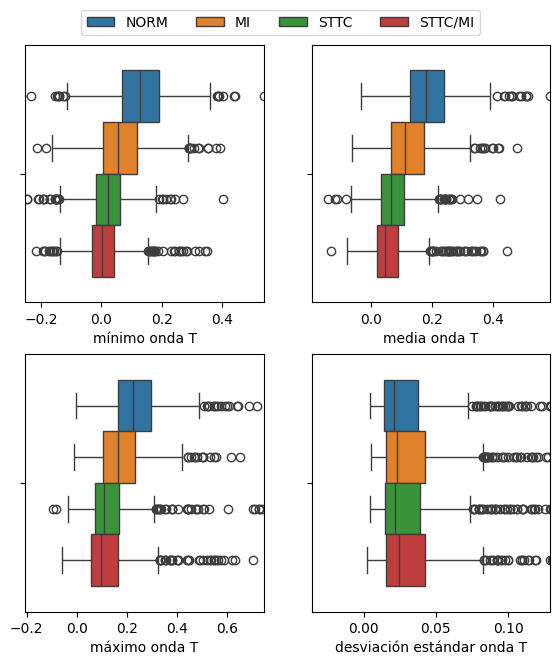

In [38]:
# columnas de la onda
columnas = ['min_T', 'media_T', 'max_T', 'sd_T']
nombres = ['mínimo onda T', 'media onda T', 'máximo onda T', 'desviación estándar onda T']
labels = ['NORM', 'MI', 'STTC', 'STTC/MI']
z = 0

# creamos la figura
fig, axs = plt.subplots(2,2, figsize=(6, 7))

#graficamos con un for
for columna, ubicacion, nombre in zip(columnas, axs.flatten(), nombres):
    Q1,Q3 = np.quantile(datos_voltajes[columna].dropna(),[0.25,0.75])
    RIQ = Q3-Q1
    li = Q1 - 2*RIQ
    ls = Q3 + 3.5*RIQ
    sns.boxplot(datos_voltajes, x=columna, hue='categoria', ax=ubicacion)
    ubicacion.set_xlim([li,ls])
    ubicacion.set_xlabel(nombre)
    ubicacion.get_legend().remove() # quitamos las leyendas individuales de los gráficos
    if z == 0: # para el primer ciclo...
        handles, _ = ubicacion.get_legend_handles_labels() # obtenemos la info de leyendas
        z =+ 1 # cambiamos z para no volver a sacar la info
# agregamos la leyenda global
fig.legend(handles, labels, loc='upper center', ncols=4, bbox_to_anchor=(0.55, 0.98))

# Ajuste manual
plt.subplots_adjust(top=0.92, right=1)
plt.savefig('../imagenes/onda_t.png', dpi=300, bbox_inches='tight')
plt.show()

In [34]:
datos_voltajes[datos_voltajes['categoria']==r'datos_leonel\sttc_mi'][columnas].describe()

,min_T,media_T,max_T,sd_T
count,596.000000,596.000000,596.000000,596.000000
mean,0.008401,0.065350,0.150186,0.042589
std,0.078421,0.074261,0.202049,0.064829
min,-0.353441,-0.132129,-0.058617,0.002311
25%,-0.032370,0.020445,0.057112,0.015158
50%,0.002712,0.046542,0.096067,0.024104
75%,0.042692,0.089046,0.165982,0.042124
max,0.349835,0.444262,2.204035,0.704812


### Correlaciones de voltajes

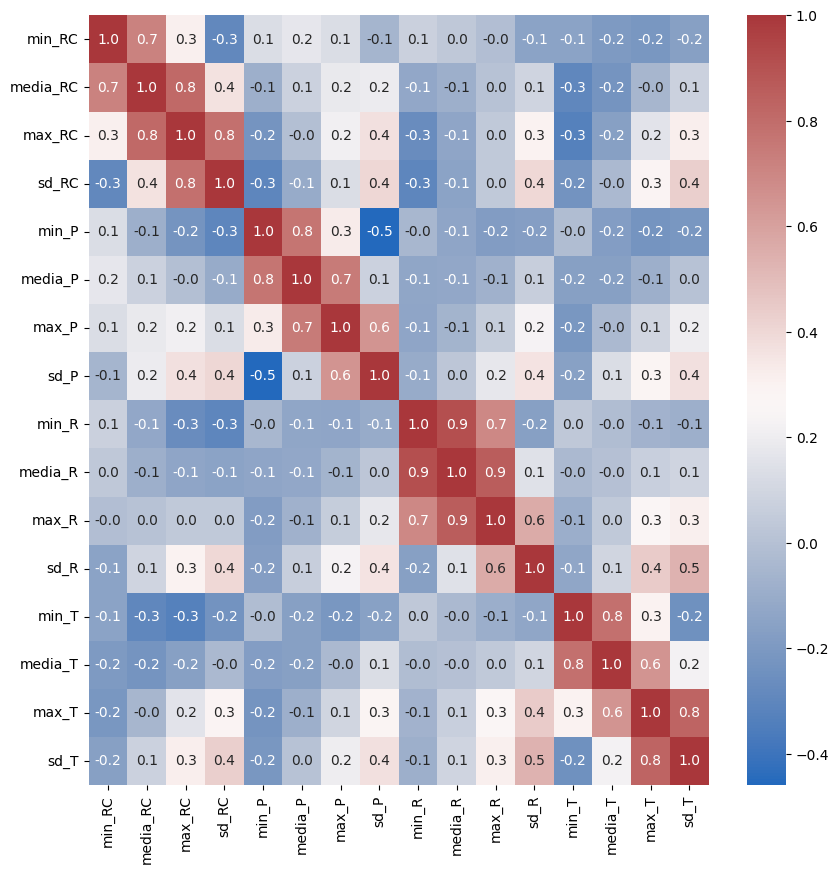

In [37]:
# matríz de correlación
fig, ax = plt.subplots(figsize=(10,10))
datos_correlacion = datos_voltajes[datos_voltajes.columns[2:-5]].corr()
sns.heatmap(datos_correlacion,
            annot=True,
            fmt=".1f",
            cmap=sns.color_palette("vlag",as_cmap=True),
            xticklabels=datos_correlacion.columns.values,
            yticklabels=datos_correlacion.columns.values)
plt.savefig('../imagenes/corr_voltajes.png', dpi=300, bbox_inches='tight')
plt.show()

### PCA voltajes

In [38]:
# PCA

# primero arreglamos los datos
datos_pca_originales = datos_voltajes.drop(['id_ecg','categoria','patient_id','sex'],axis=1).dropna() # quitamos algunas columnas no numéricas y los NA.
scaler = StandardScaler() # llamamos al normalizador
datos_pca = scaler.fit_transform(datos_pca_originales) # normalizamos

# aplicamos PCA
pca = PCA(n_components=2) # llamamos al PCAdor
datos_pca = pca.fit_transform(datos_pca) # aplicamos PCA

# calculamos los pesos de cada variable en cada componente (se usan abajo)
componentes = pca.components_  # Matriz de pesos: cada fila es un componente (PC1, PC2, ...)
componentes = pd.DataFrame(componentes, columns=datos_pca_originales.columns) # transformamos los valores en un df

print(pca.explained_variance_ratio_)
print(sum(pca.explained_variance_ratio_))

[0.21915555 0.14639427]
0.36554981968182965


<Figure size 800x600 with 0 Axes>

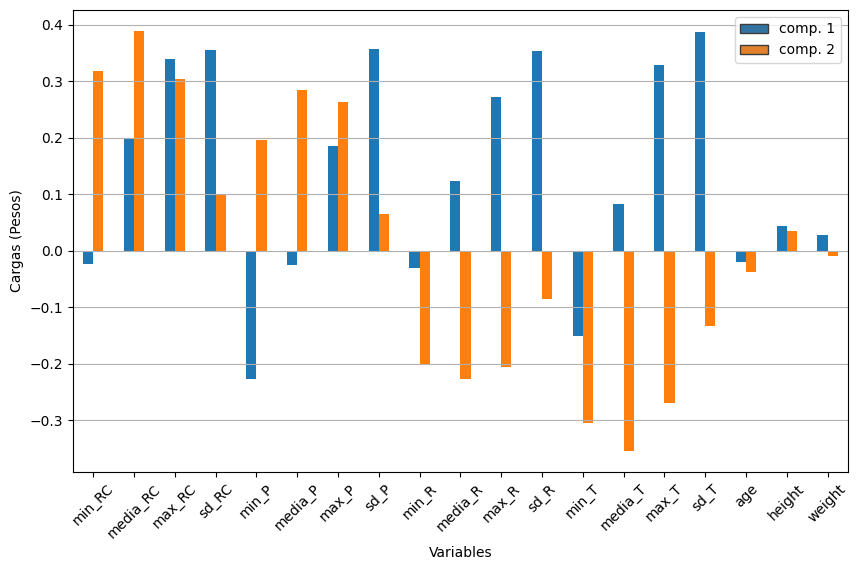

In [39]:
# gráfico de barras con el peso de cada variable en cada componente principal
plt.figure(figsize=(8, 6))
componentes.T.plot(kind='bar', figsize=(10, 6), legend=True)
plt.ylabel('Cargas (Pesos)')
plt.xlabel('Variables')
plt.grid(axis='y')
plt.xticks(rotation=45)
plt.legend(handles, ['comp. 1','comp. 2'], loc='upper right')
plt.savefig('../imagenes/pca_voltajes.png', dpi=300, bbox_inches='tight')
plt.show()

## Datos Tiempos

In [5]:
datos_tiempos.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2400 entries, 0 to 2399
Data columns (total 31 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id_ecg      2400 non-null   float64
 1   categoria   2400 non-null   object 
 2   min_RC      2375 non-null   float64
 3   media_RC    2375 non-null   float64
 4   max_RC      2375 non-null   float64
 5   sd_RC       2375 non-null   float64
 6   min_PQ      2375 non-null   float64
 7   media_PQ    2375 non-null   float64
 8   max_PQ      2375 non-null   float64
 9   sd_PQ       2375 non-null   float64
 10  min_QR      2375 non-null   float64
 11  media_QR    2375 non-null   float64
 12  max_QR      2375 non-null   float64
 13  sd_QR       2375 non-null   float64
 14  min_RS      2375 non-null   float64
 15  media_RS    2375 non-null   float64
 16  max_RS      2375 non-null   float64
 17  sd_RS       2375 non-null   float64
 18  min_ST      2375 non-null   float64
 19  media_ST    2375 non-null   floa

### segmento PQ

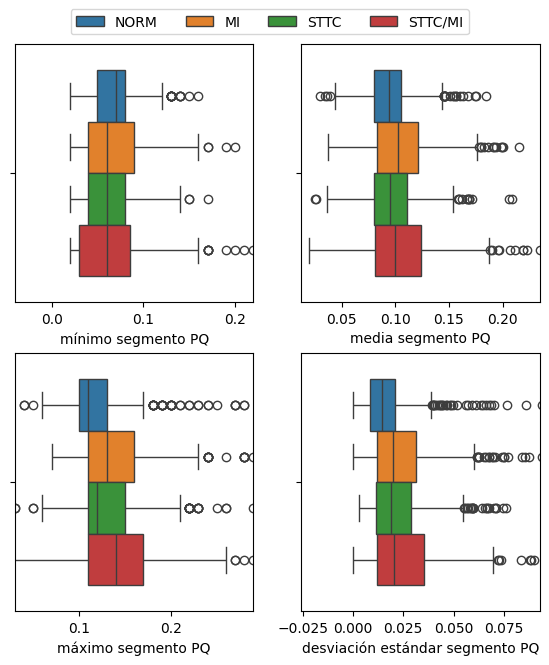

In [7]:
# columnas de la onda
columnas = ['min_PQ', 'media_PQ', 'max_PQ', 'sd_PQ']
nombres = ['mínimo segmento PQ', 'media segmento PQ', 'máximo segmento PQ', 'desviación estándar segmento PQ']
labels = ['NORM', 'MI', 'STTC', 'STTC/MI']
z = 0

# creamos la figura
fig, axs = plt.subplots(2,2, figsize=(6, 7))

#graficamos con un for
for columna, ubicacion, nombre in zip(columnas, axs.flatten(), nombres):
    Q1,Q3 = np.quantile(datos_tiempos[columna].dropna(),[0.25,0.75])
    RIQ = Q3-Q1
    li = Q1 - 2*RIQ
    ls = Q3 + 3.5*RIQ
    sns.boxplot(datos_tiempos, x=columna, hue='categoria', ax=ubicacion)
    ubicacion.set_xlim([li,ls])
    ubicacion.set_xlabel(nombre)
    ubicacion.get_legend().remove() # quitamos las leyendas individuales de los gráficos
    if z == 0: # para el primer ciclo...
        handles, _ = ubicacion.get_legend_handles_labels() # obtenemos la info de leyendas
        z =+ 1 # cambiamos z para no volver a sacar la info
# agregamos la leyenda global
fig.legend(handles, labels, loc='upper center', ncols=4, bbox_to_anchor=(0.55, 0.98))

# Ajuste manual
plt.subplots_adjust(top=0.92, right=1)
plt.savefig('../imagenes/segmento_PQ.png', dpi=300, bbox_inches='tight')
plt.show()

In [9]:
data = datos_tiempos[datos_tiempos['categoria']==r'datos_leonel\other']['sd_PQ']
Q1,Q3 = np.quantile(data.dropna(),[0.25,0.75])
print(Q3-Q1)

0.012156405956817


In [10]:
data = datos_tiempos[datos_tiempos['categoria']==r'datos_leonel\sttc_mi']['sd_PQ']
Q1,Q3 = np.quantile(data.dropna(),[0.25,0.75])
print(Q3-Q1)

0.0232132372523544


### Segmento QR

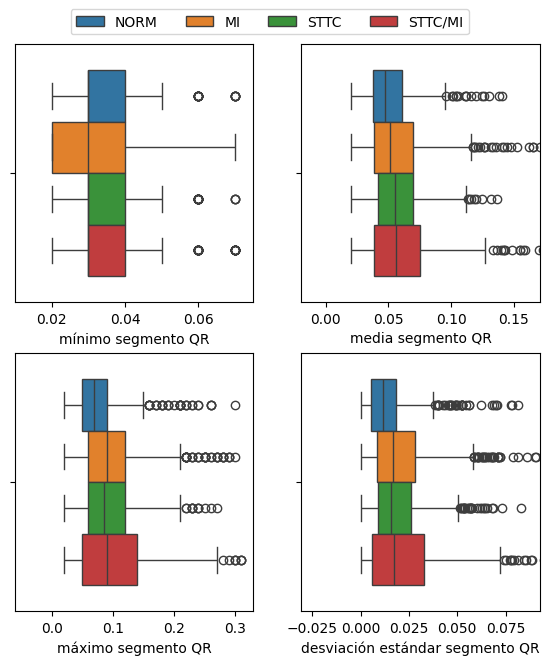

In [8]:
# columnas de la onda
columnas = ['min_QR', 'media_QR', 'max_QR', 'sd_QR']
nombres = ['mínimo segmento QR', 'media segmento QR', 'máximo segmento QR', 'desviación estándar segmento QR']
labels = ['NORM', 'MI', 'STTC', 'STTC/MI']
z = 0

# creamos la figura
fig, axs = plt.subplots(2,2, figsize=(6, 7))

#graficamos con un for
for columna, ubicacion, nombre in zip(columnas, axs.flatten(), nombres):
    Q1,Q3 = np.quantile(datos_tiempos[columna].dropna(),[0.25,0.75])
    RIQ = Q3-Q1
    li = Q1 - 2*RIQ
    ls = Q3 + 3.5*RIQ
    sns.boxplot(datos_tiempos, x=columna, hue='categoria', ax=ubicacion)
    ubicacion.set_xlim([li,ls])
    ubicacion.set_xlabel(nombre)
    ubicacion.get_legend().remove() # quitamos las leyendas individuales de los gráficos
    if z == 0: # para el primer ciclo...
        handles, _ = ubicacion.get_legend_handles_labels() # obtenemos la info de leyendas
        z =+ 1 # cambiamos z para no volver a sacar la info
# agregamos la leyenda global
fig.legend(handles, labels, loc='upper center', ncols=4, bbox_to_anchor=(0.55, 0.98))

# Ajuste manual
plt.subplots_adjust(top=0.92, right=1)
plt.savefig('../imagenes/segmento_QR.png', dpi=300, bbox_inches='tight')
plt.show()

<Axes: xlabel='min_QR', ylabel='Count'>

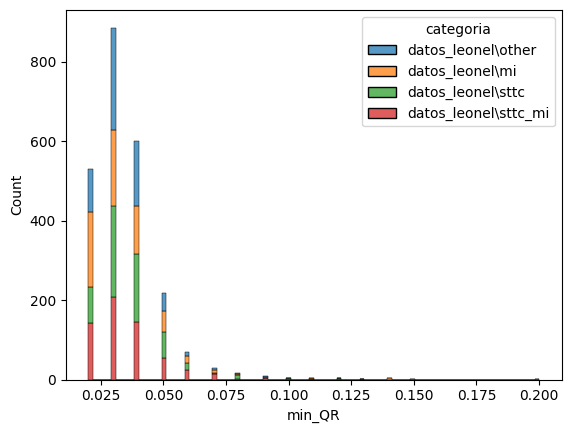

In [ ]:
# el mínimo del segmento QR es complejo porque es un segmento corto en general y 
# el mínimo termina tocando los límites de la definición de los electrocardiogramas;
# cada punto de la señal de ECG a muestreo 100 representa 0.01 segundos, es por eso
# que obtenemos el resultado extraño en esta gráfica.

sns.histplot(datos_tiempos, x='min_QR', hue='categoria', multiple="stack")

### segmento RS

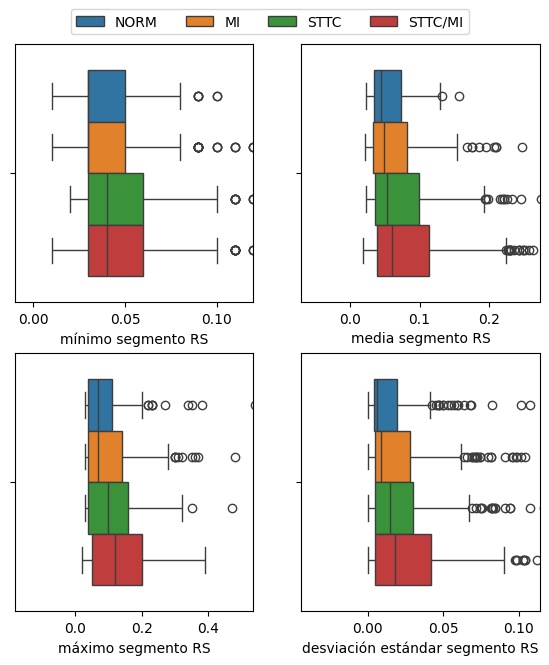

In [27]:
# columnas de la onda
columnas = ['min_RS', 'media_RS', 'max_RS', 'sd_RS']
nombres = ['mínimo segmento RS', 'media segmento RS', 'máximo segmento RS', 'desviación estándar segmento RS']
labels = ['NORM', 'MI', 'STTC', 'STTC/MI']
z = 0

# creamos la figura
fig, axs = plt.subplots(2,2, figsize=(6, 7))

#graficamos con un for
for columna, ubicacion, nombre in zip(columnas, axs.flatten(), nombres):
    Q1,Q3 = np.quantile(datos_tiempos[columna].dropna(),[0.25,0.75])
    RIQ = Q3-Q1
    li = Q1 - 2*RIQ
    ls = Q3 + 3.5*RIQ
    sns.boxplot(datos_tiempos, x=columna, hue='categoria', ax=ubicacion)
    ubicacion.set_xlim([li,ls])
    ubicacion.set_xlabel(nombre)
    ubicacion.get_legend().remove() # quitamos las leyendas individuales de los gráficos
    if z == 0: # para el primer ciclo...
        handles, _ = ubicacion.get_legend_handles_labels() # obtenemos la info de leyendas
        z =+ 1 # cambiamos z para no volver a sacar la info
# agregamos la leyenda global
fig.legend(handles, labels, loc='upper center', ncols=4, bbox_to_anchor=(0.55, 0.98))

# Ajuste manual
plt.subplots_adjust(top=0.92, right=1)
plt.savefig('../imagenes/segmento_RS.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
data = datos_tiempos[datos_tiempos['categoria'] == r'datos_leonel\mi']['sd_RS']
Q1,Q3 = np.quantile(data.dropna(),[0.25,0.75])
print(Q3-Q1)

0.023319883830503003


In [17]:
data = datos_tiempos[datos_tiempos['categoria'] == r'datos_leonel\sttc_mi']['sd_RS']
Q1,Q3 = np.quantile(data.dropna(),[0.25,0.75])
print(Q3-Q1)

0.0366737640201716


### Segmento ST

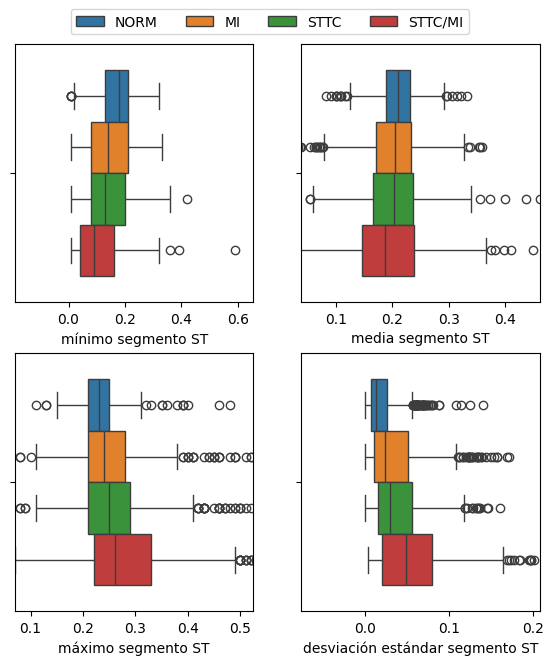

In [28]:
# columnas de la onda
columnas = ['min_ST', 'media_ST', 'max_ST', 'sd_ST']
nombres = ['mínimo segmento ST', 'media segmento ST', 'máximo segmento ST', 'desviación estándar segmento ST']
labels = ['NORM', 'MI', 'STTC', 'STTC/MI']
z = 0

# creamos la figura
fig, axs = plt.subplots(2,2, figsize=(6, 7))

#graficamos con un for
for columna, ubicacion, nombre in zip(columnas, axs.flatten(), nombres):
    Q1,Q3 = np.quantile(datos_tiempos[columna].dropna(),[0.25,0.75])
    RIQ = Q3-Q1
    li = Q1 - 2*RIQ
    ls = Q3 + 3.5*RIQ
    sns.boxplot(datos_tiempos, x=columna, hue='categoria', ax=ubicacion)
    ubicacion.set_xlim([li,ls])
    ubicacion.set_xlabel(nombre)
    ubicacion.get_legend().remove() # quitamos las leyendas individuales de los gráficos
    if z == 0: # para el primer ciclo...
        handles, _ = ubicacion.get_legend_handles_labels() # obtenemos la info de leyendas
        z =+ 1 # cambiamos z para no volver a sacar la info
# agregamos la leyenda global
fig.legend(handles, labels, loc='upper center', ncols=4, bbox_to_anchor=(0.55, 0.98))

# Ajuste manual
plt.subplots_adjust(top=0.92, right=1)
plt.savefig('../imagenes/segmento_ST.png', dpi=300, bbox_inches='tight')
plt.show()

In [21]:
columnas = ['media_PQ','media_QR','media_RS','media_ST','media_TP']
datos_tiempos[columnas].mean()

media_PQ    0.099488
media_QR    0.056699
media_RS    0.068008
media_ST    0.201385
media_TP    0.402389
dtype: float64

In [42]:
columnas = ['categoria','media_ST']
aux = datos_tiempos[columnas].groupby('categoria').describe()
aux. columns = aux.columns.droplevel(0)
aux['RIQ'] = aux['75%']-aux['25%']
aux

,count,mean,std,min,25%,50%,75%,max,RIQ
categoria,,,,,,,,,
datos_leonel\mi,591.0,0.201161,0.053689,0.018571,0.171538,0.204167,0.233636,0.358889,0.062098
datos_leonel\other,597.0,0.209419,0.034808,0.082000,0.188182,0.209091,0.231000,0.332500,0.042818
datos_leonel\sttc,592.0,0.203096,0.056514,0.053913,0.165000,0.203333,0.237378,0.461111,0.072378
datos_leonel\sttc_mi,595.0,0.191845,0.071017,0.021000,0.146410,0.186364,0.237500,0.774000,0.091090


### segmento TP

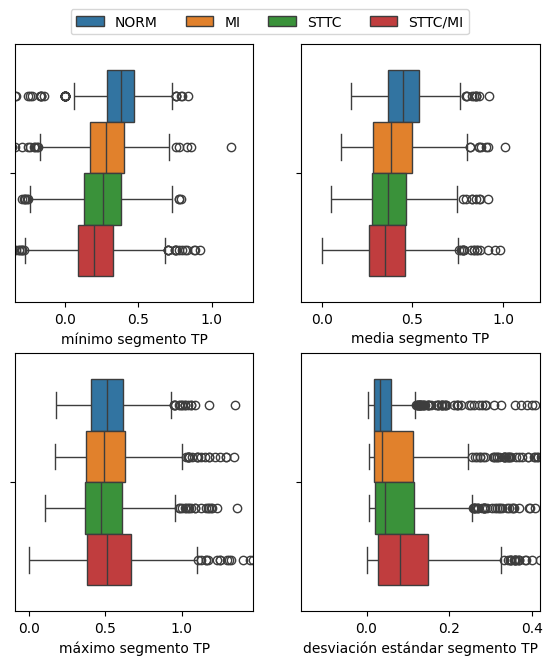

In [29]:
# columnas de la onda
columnas = ['min_TP', 'media_TP', 'max_TP', 'sd_TP']
nombres = ['mínimo segmento TP', 'media segmento TP', 'máximo segmento TP', 'desviación estándar segmento TP']
labels = ['NORM', 'MI', 'STTC', 'STTC/MI']
z = 0

# creamos la figura
fig, axs = plt.subplots(2,2, figsize=(6, 7))

#graficamos con un for
for columna, ubicacion, nombre in zip(columnas, axs.flatten(), nombres):
    Q1,Q3 = np.quantile(datos_tiempos[columna].dropna(),[0.25,0.75])
    RIQ = Q3-Q1
    li = Q1 - 2*RIQ
    ls = Q3 + 3.5*RIQ
    sns.boxplot(datos_tiempos, x=columna, hue='categoria', ax=ubicacion)
    ubicacion.set_xlim([li,ls])
    ubicacion.set_xlabel(nombre)
    ubicacion.get_legend().remove() # quitamos las leyendas individuales de los gráficos
    if z == 0: # para el primer ciclo...
        handles, _ = ubicacion.get_legend_handles_labels() # obtenemos la info de leyendas
        z =+ 1 # cambiamos z para no volver a sacar la info
# agregamos la leyenda global
fig.legend(handles, labels, loc='upper center', ncols=4, bbox_to_anchor=(0.55, 0.98))

# Ajuste manual
plt.subplots_adjust(top=0.92, right=1)
plt.savefig('../imagenes/segmento_TP.png', dpi=300, bbox_inches='tight')
plt.show()

### Correlaciones Tiempos

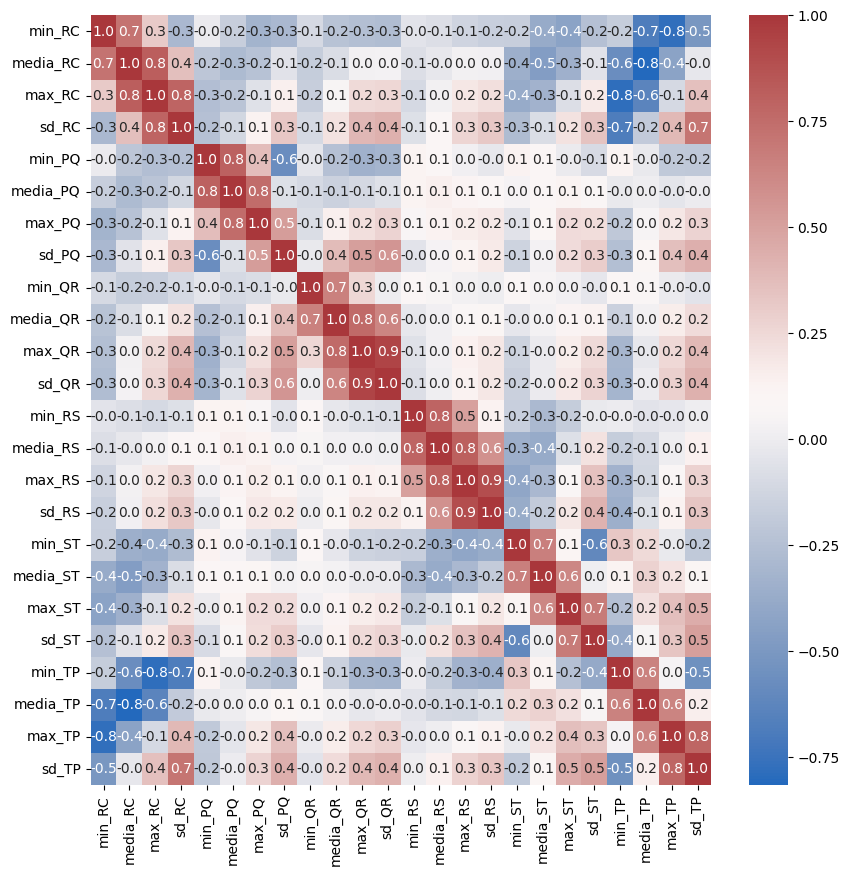

In [40]:
# matríz de correlación
fig, ax = plt.subplots(figsize=(10,10))
datos_correlacion = datos_tiempos[datos_tiempos.columns[2:-5]].corr()
sns.heatmap(datos_correlacion,
            annot=True,
            fmt=".1f",
            cmap=sns.color_palette("vlag",as_cmap=True),
            xticklabels=datos_correlacion.columns.values,
            yticklabels=datos_correlacion.columns.values)
plt.savefig('../imagenes/corr_tiempos.png', dpi=300, bbox_inches='tight')
plt.show()

### PCA tiempos

In [41]:
# PCA

# primero arreglamos los datos
datos_pca_originales = datos_tiempos.drop(['id_ecg','categoria','patient_id','sex'],axis=1).dropna() # quitamos algunas columnas no numéricas y los NA.
scaler = StandardScaler() # llamamos al normalizador
datos_pca = scaler.fit_transform(datos_pca_originales) # normalizamos

# aplicamos PCA
pca = PCA(n_components=2) # llamamos al PCAdor
datos_pca = pca.fit_transform(datos_pca) # aplicamos PCA

# calculamos los pesos de cada variable en cada componente (se usan abajo)
componentes = pca.components_  # Matriz de pesos: cada fila es un componente (PC1, PC2, ...)
componentes = pd.DataFrame(componentes, columns=datos_pca_originales.columns) # transformamos los valores en un df

print(pca.explained_variance_ratio_)
print(sum(pca.explained_variance_ratio_))

[0.20923052 0.1742168 ]
0.38344731618810085


<Figure size 800x600 with 0 Axes>

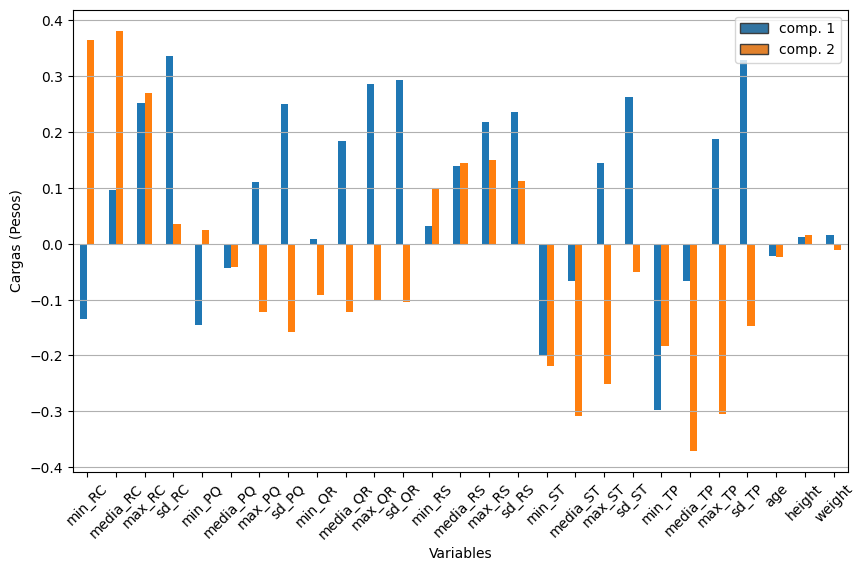

In [42]:
# gráfico de barras con el peso de cada variable en cada componente principal
plt.figure(figsize=(8, 6))
componentes.T.plot(kind='bar', figsize=(10, 6), legend=True)
plt.ylabel('Cargas (Pesos)')
plt.xlabel('Variables')
plt.grid(axis='y')
plt.xticks(rotation=45)
plt.legend(handles, ['comp. 1','comp. 2'], loc='upper right')
plt.savefig('../imagenes/pca_tiempos.png', dpi=300, bbox_inches='tight')
plt.show()